In [13]:
import math

# Training data: two features, binary labels
xs = [[1, 2], [2, 1], [2, 3], [3, 2],
      [6, 7], [7, 6], [7, 8], [8, 7]]
ys = [0, 0, 0, 0, 1, 1, 1, 1]

# Parameters and learning rate
w1, w2, b = 0.0, 0.0, 0.0
lr = 0.1

<div style="text-align: center;">
  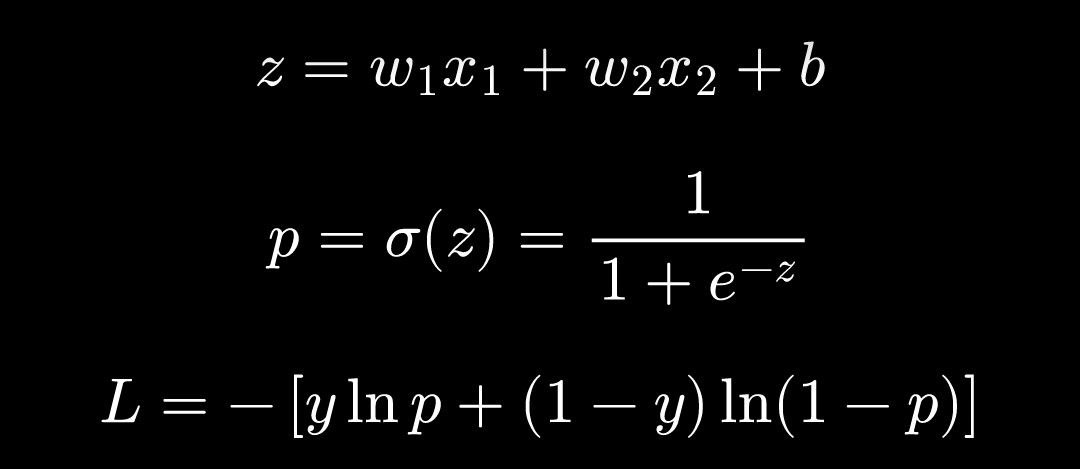
</div>

<div style="text-align: center;">
  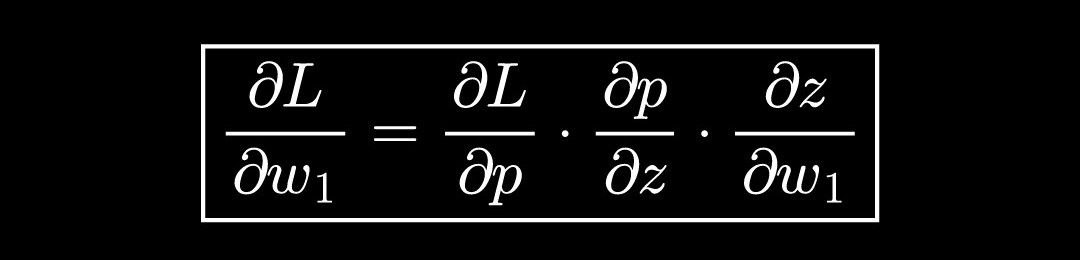
</div>

<div style="display: flex; justify-content: center; align-items: flex-start; gap: 12px; flex-wrap: nowrap;">
  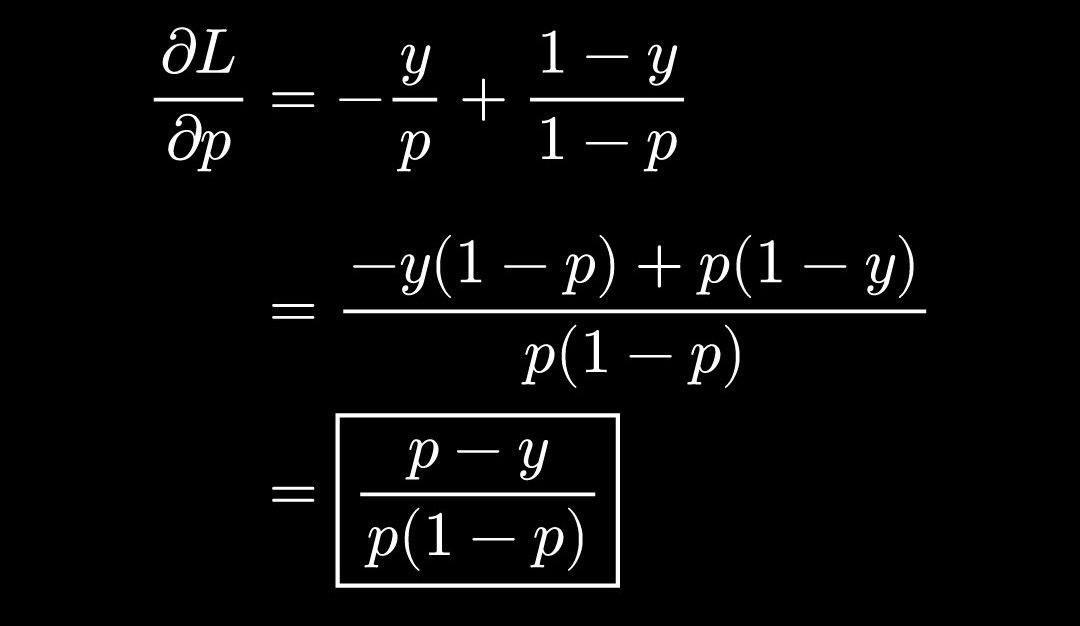
  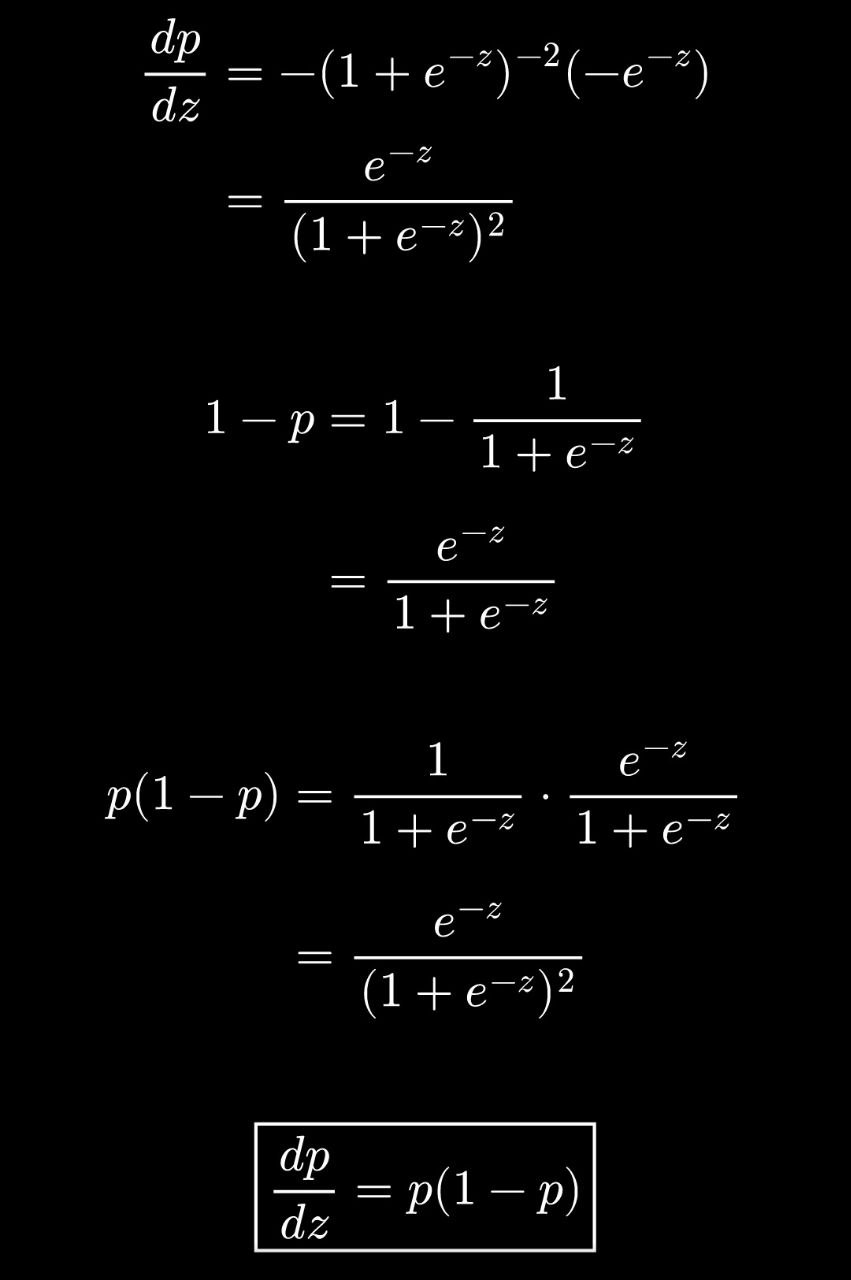
  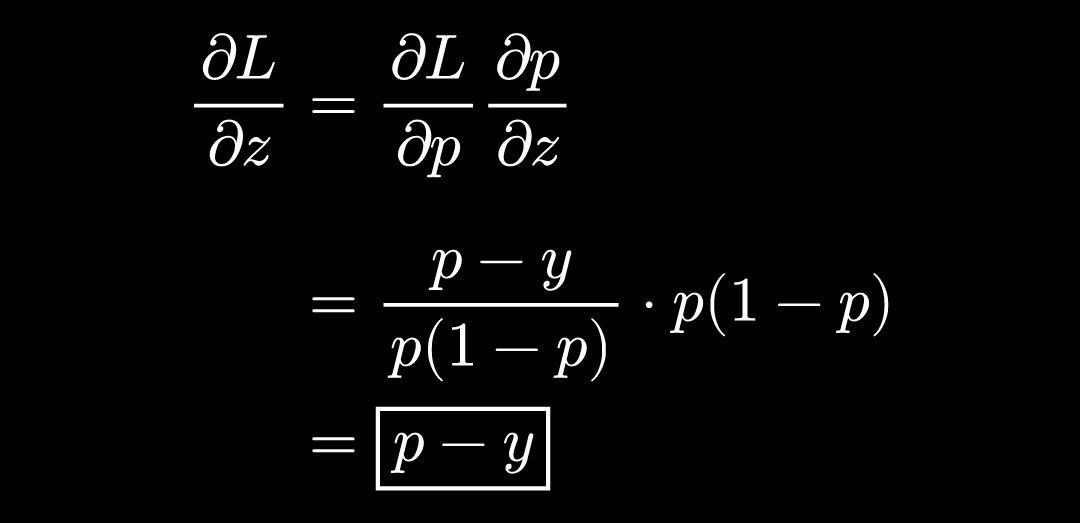
</div>

<div style="text-align: center;">
  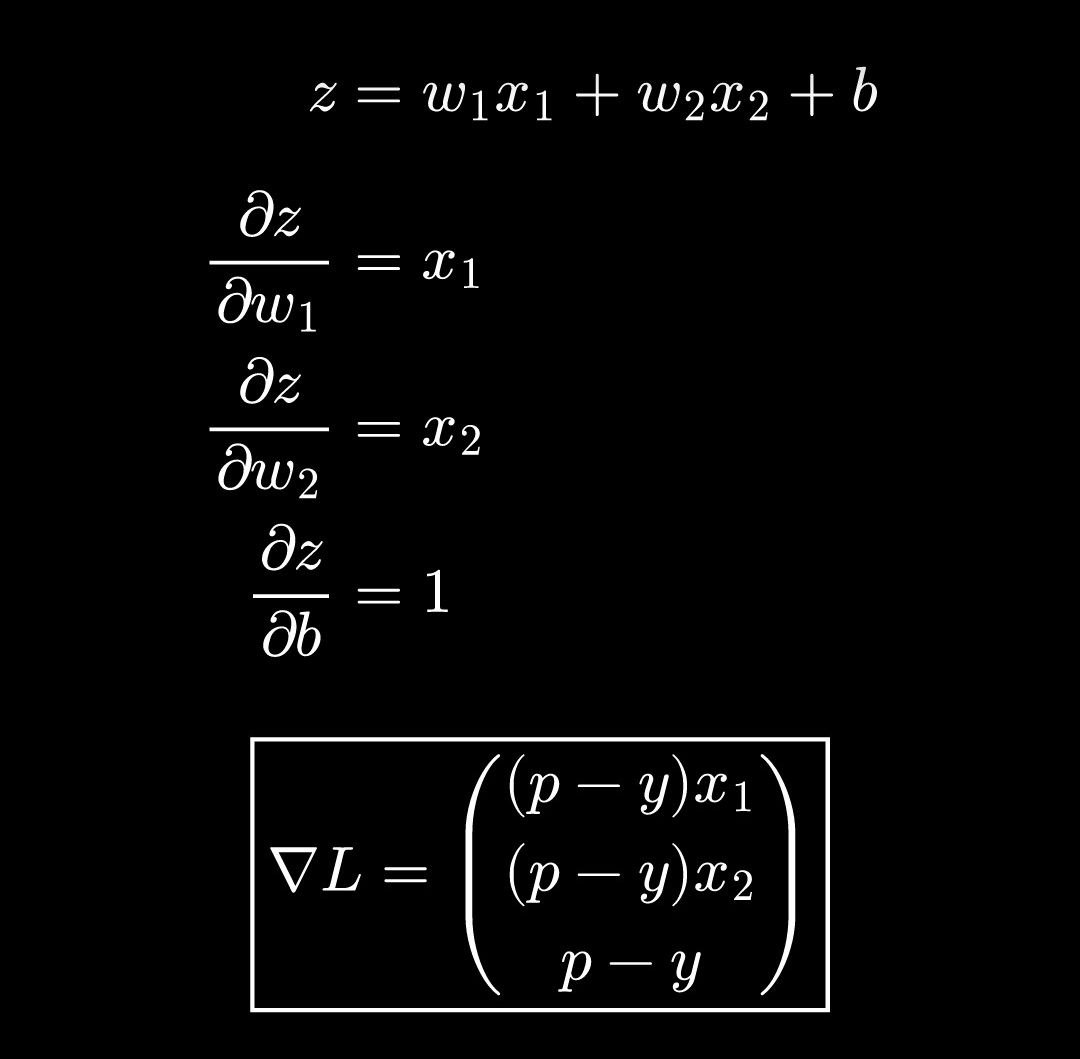
</div>

In [14]:
for epoch in range(200):
    # SGD: update parameters after EACH sample
    for x, y in zip(xs, ys):

        # Forward pass: weighted sum + sigmoid
        z = w1 * x[0] + w2 * x[1] + b
        p = 1 / (1 + math.exp(-z))

        # Binary cross-entropy gradient: dL/dz
        err = p - y

        # Partial derivatives of the loss
        dw1 = err * x[0]
        dw2 = err * x[1]
        db = err

        # SGD: immediate parameter update
        w1 -= lr * dw1
        w2 -= lr * dw2
        b -= lr * db

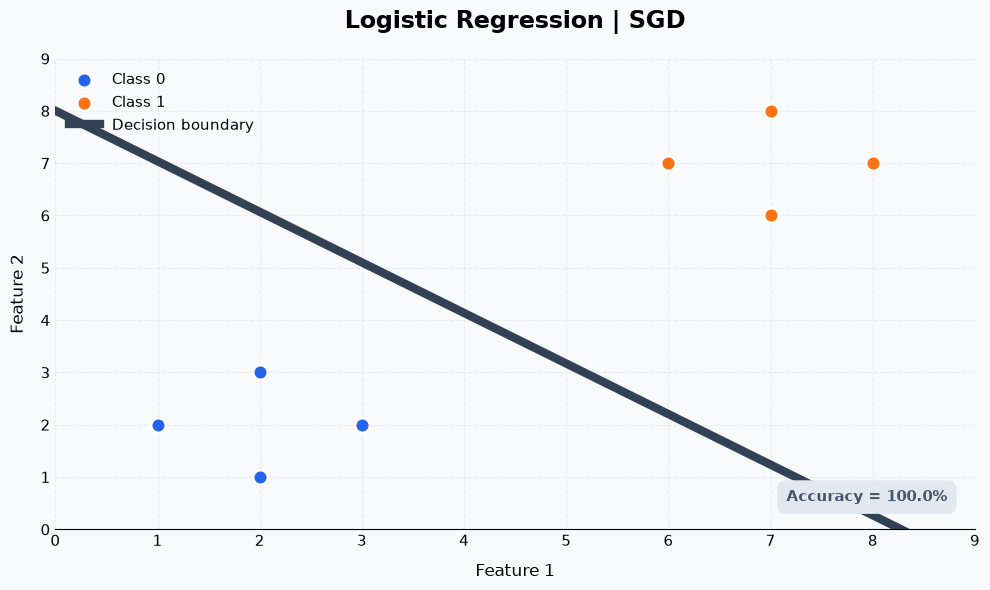

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Convert training data to NumPy arrays
X = np.array(xs)
y = np.array(ys)

# Decision boundary: sigmoid(z) = 0.5 => z = 0
# w1*x1 + w2*x2 + b = 0
x_line = np.linspace(X[:, 0].min() - 1,
                     X[:, 0].max() + 1, 20)
# x_line are x1, y_line are x2 in: w1*x1 + w2*x2 + b = 0
y_line = -(w1 * x_line + b) / w2

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor("#f8fafc")
ax.set_facecolor("#f8fafc")

# Plot samples by class
for label, color, name in [
    (0, "#2563eb", "Class 0"),
    (1, "#f97316", "Class 1")
]:
    points = X[y == label]
    ax.scatter(points[:, 0], points[:, 1],
               s=110, color=color, edgecolors="white",
               linewidths=1.8, zorder=3, label=name)

# Plot learned decision boundary
ax.plot(x_line, y_line, color="#334155",
        linewidth=6, label="Decision boundary")


# Model accuracy
z = w1 * X[:, 0] + w2 * X[:, 1] + b
probs = 1 / (1 + np.exp(-z))
predictions = (probs >= 0.5).astype(int)
accuracy = np.mean(predictions == y)

# Styling
ax.set_title("Logistic Regression | SGD",
             fontsize=17, fontweight="bold", pad=22)
ax.set_xlabel("Feature 1", fontsize=12, labelpad=10)
ax.set_ylabel("Feature 2", fontsize=12, labelpad=10)

ax.grid(True, linestyle="--", alpha=0.18)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(length=0, labelsize=11)
ax.legend(frameon=False, fontsize=11, loc="upper left")

# Model performance
ax.text(0.97, 0.06, f"Accuracy = {accuracy:.1%}",
        transform=ax.transAxes, ha="right",
        fontsize=11, fontweight="bold", color="#475569",
        bbox=dict(boxstyle="round,pad=0.6",
                  facecolor="#e2e8f0", edgecolor="none"))

ax.set_xlim(X[:, 0].min() - 1, X[:, 0].max() + 1)
ax.set_ylim(X[:, 1].min() - 1, X[:, 1].max() + 1)

plt.tight_layout()
plt.show()
